# Challenge 1 – Classification explicable : analyse du cas Telco Customer Churn

Ce notebook rejoue, sans interface, le même pipeline que l'application (modules `backend/app`). Il sert de trace reproductible des résultats cités dans le one-pager.

In [1]:
import sys, warnings
sys.path.insert(0, '../backend')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, shap
from app import data as D, prep as P, models as MD, metrics as MT, explain as X
from app.state import Session
%matplotlib inline

## 1. Données (téléchargement automatique)

In [2]:
df, target, positive = D.load_preset('telco')
s = Session(); s.df, s.target, s.positive, s.name = df, target, positive, 'telco'
print(df.shape, '| taux de résiliation :', round(D.binarize(df[target], positive).mean(), 3))
df.head()

(7043, 20) | taux de résiliation : 0.265


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
summ = D.summary(df, target, positive, 'telco')
pd.DataFrame(summ['columns'])[['name','kind','n_unique','missing']].T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
name,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
kind,categorical,numeric,categorical,categorical,numeric,categorical,categorical,categorical,categorical,categorical,categorical,categorical,categorical,categorical,categorical,categorical,categorical,numeric,numeric,categorical
n_unique,2,2,2,2,73,2,3,3,3,3,3,3,3,3,3,2,4,1585,6530,2
missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,11,0


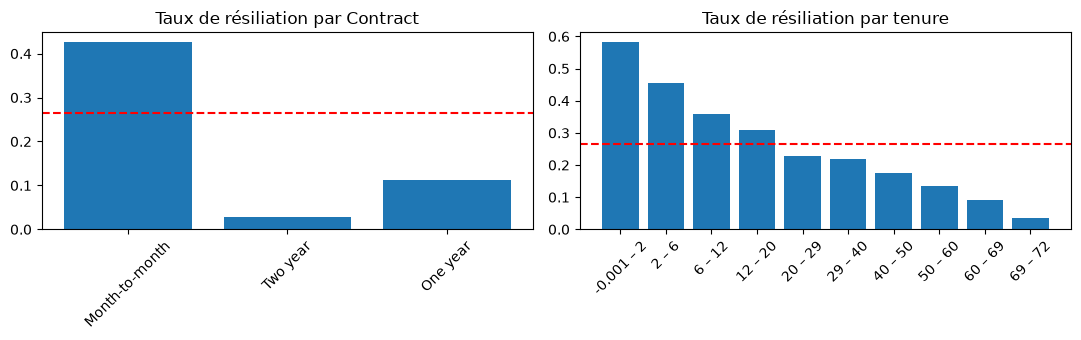

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, col in zip(ax, ['Contract', 'tenure']):
    v = D.column_view(df, col, target, positive)
    a.bar([r['label'] for r in v['rate']], [r['rate'] for r in v['rate']]); a.axhline(v['base_rate'], ls='--', c='r')
    a.set_title(f'Taux de résiliation par {col}'); a.tick_params(axis='x', rotation=45)
plt.tight_layout()

## 2. Préparation

In [5]:
feats = [c for c in df.columns if c != target]
cfg = dict(features=feats, num_impute='median', cat_impute='mode', scaling='standard', test_size=0.25, random_state=42, stratify=True)
info = P.build(s, cfg); {k: v for k, v in info.items() if k != 'encoded_names'}

{'n_train': 5282,
 'n_test': 1761,
 'n_features_in': 19,
 'n_features_encoded': 45,
 'numeric': ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'],
 'categorical': ['gender',
  'Partner',
  'Dependents',
  'PhoneService',
  'MultipleLines',
  'InternetService',
  'OnlineSecurity',
  'OnlineBackup',
  'DeviceProtection',
  'TechSupport',
  'StreamingTV',
  'StreamingMovies',
  'Contract',
  'PaperlessBilling',
  'PaymentMethod'],
 'train_pos_rate': 0.2654297614539947,
 'test_pos_rate': 0.26519023282226006,
 'dropped_rows': 0}

## 3. Modélisation avec optimisation des hyperparamètres

In [6]:
res = {}
for name in ['logreg', 'tree', 'knn', 'rf', 'xgb']:
    est, inf = MD.train_one(name, {}, tune=True, balance=False, Z=s.Z_train, y=s.y_train.values)
    s.models[name] = dict(est=est, info=inf, p_test=est.predict_proba(s.Z_test)[:, 1], label=MD.CATALOG[name]['label'])
    res[name] = inf
pd.DataFrame(res).T[['params', 'cv_auc', 'train_seconds']]

,params,cv_auc,train_seconds
logreg,"{'C': 10.0, 'max_iter': 1000}",0.844035,0.25
tree,"{'max_depth': 12, 'min_samples_leaf': 50}",0.832406,0.62
knn,{'n_neighbors': 101},0.832424,0.6
rf,"{'n_estimators': 200, 'max_depth': 16, 'min_sa...",0.848199,10.14
xgb,"{'n_estimators': 200, 'max_depth': 3, 'learnin...",0.847469,6.25


## 4. Évaluation

In [7]:
thr = 0.35
rows = []
for n, m in s.models.items():
    e = MT.evaluate(s.y_test.values, m['p_test'], thr, with_curves=False)
    rows.append({'modèle': m['label'], **{k: round(e[k], 3) for k in ['auc', 'pr_auc', 'gini', 'ks', 'precision', 'recall', 'f1']}})
pd.DataFrame(rows).set_index('modèle').sort_values('auc', ascending=False)

,auc,pr_auc,gini,ks,precision,recall,f1
modèle,,,,,,,
XGBoost,0.848,0.656,0.696,0.549,0.575,0.715,0.637
Régression logistique,0.846,0.633,0.692,0.540,0.554,0.713,0.624
Random Forest,0.846,0.650,0.692,0.555,0.565,0.713,0.631
k plus proches voisins,0.834,0.616,0.668,0.513,0.513,0.782,0.619
Arbre de décision,0.831,0.627,0.663,0.524,0.573,0.662,0.614


Text(0.5, 1.0, 'Courbes ROC (test)')

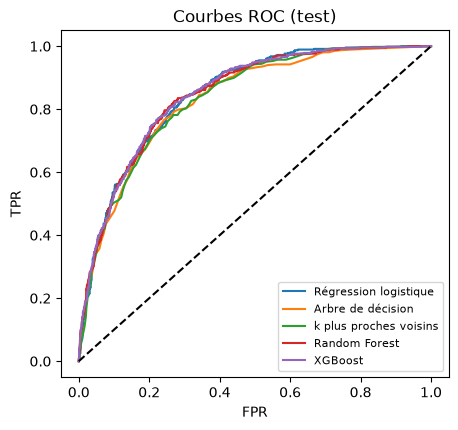

In [8]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(5, 4.5))
for n, m in s.models.items():
    f, t, _ = roc_curve(s.y_test, m['p_test']); plt.plot(f, t, label=m['label'])
plt.plot([0, 1], [0, 1], 'k--'); plt.xlabel('FPR'); plt.ylabel('TPR'); plt.legend(fontsize=8); plt.title('Courbes ROC (test)')

## 5. Explicabilité globale

In [9]:
perm = {n: X.permutation(s, n) for n in ['logreg', 'xgb']}
pd.DataFrame({n: pd.Series({i['feature']: round(i['importance'], 4) for i in p['items']}) for n, p in perm.items()}).sort_values('xgb', ascending=False).head(10)

,logreg,xgb
Contract,0.0307,0.0767
tenure,0.1972,0.0541
InternetService,0.1234,0.0101
OnlineSecurity,0.0090,0.0084
MonthlyCharges,0.1246,0.0079
TotalCharges,0.0150,0.0053
PaymentMethod,0.0033,0.0036
TechSupport,0.0026,0.0024
PaperlessBilling,0.0009,0.0013
MultipleLines,0.0084,0.0013


Text(0.5, 1.0, 'SHAP summary – XGBoost')

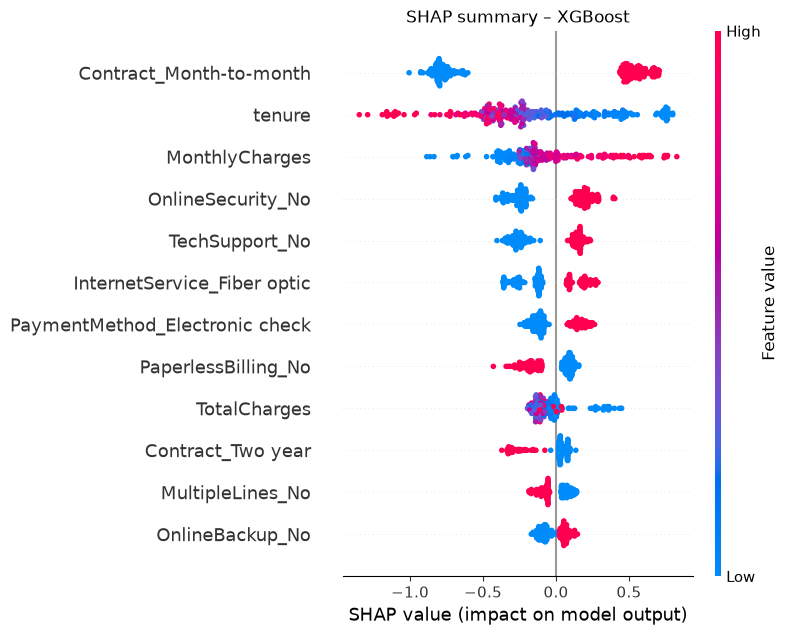

In [10]:
g = X.shap_global(s, 'xgb')
idx, sv = s.cache[('xgb', 'shap_raw')]
shap.summary_plot(sv, s.M_test[idx], feature_names=s.names, max_display=12, show=False)
plt.title('SHAP summary – XGBoost')

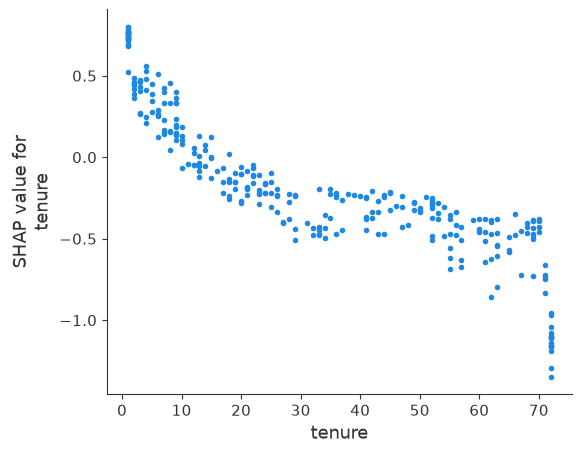

In [11]:
shap.dependence_plot('tenure', sv, s.M_test[idx], feature_names=s.names, interaction_index=None, show=False)

## 6. Explication locale : SHAP vs LIME

In [12]:
p = s.models['xgb']['p_test']; i = int(np.argsort(-p)[3])
r = X.local(s, 'xgb', 0.35, test_index=i)
print(r['sentence']); print('accord SHAP/LIME :', r['agreement'])
pd.DataFrame(r['comparison'])[['label', 'shap', 'lime', 'same_sign']].round(3)

Le risque « Churn = Yes » est élevé (probabilité 88%, seuil 35%), principalement à cause de tenure = 1 et Contract = Month-to-month.
accord SHAP/LIME : {'top5_overlap': 4, 'sign_agreement': 1.0, 'spearman': 0.9030303030303028, 'n_common': 10}


,label,shap,lime,same_sign
0,tenure = 1,0.729,0.130,True
1,Contract = Month-to-month,0.702,0.176,True
2,TotalCharges = 84.6,0.332,NaN,None
3,OnlineSecurity = No,0.226,0.059,True
4,TechSupport = No,0.217,0.054,True
5,InternetService = Fiber optic,0.199,0.065,True
6,PaymentMethod = Electronic check,0.170,0.041,True
7,MonthlyCharges = 84.6,0.141,NaN,None
8,PaperlessBilling ≠ No,0.104,0.047,True
9,MultipleLines ≠ No,0.104,0.027,True


## 7. Variables sensibles

In [13]:
a = X.sensitive_audit(s, 'xgb', 0.35)
pd.DataFrame([{k: f[k] for k in ['feature', 'used_in_model', 'shap_share', 'parity_gap']} for f in a['features']]).round(3)

,feature,used_in_model,shap_share,parity_gap
0,gender,True,0.002,0.026
1,SeniorCitizen,True,0.014,0.303
2,Partner,True,0.000,0.236
3,Dependents,True,0.012,0.255


## 8. Analyse critique (résultats de cette exécution : graine 42, seuil 0,35)

**Cohérence SHAP / LIME / intuition métier.** Sur l'individu expliqué, SHAP et LIME s'accordent sur le signe des 10 variables comparées et sur 4 des 5 premières ; la corrélation de rang est de 0,90. Les deux désignent l'ancienneté très faible (`tenure`) et le contrat mensuel comme moteurs du risque, ce qui est cohérent avec l'intuition métier (un client récent, sans engagement, part plus facilement). Les amplitudes ne sont pas comparables (SHAP en log-odds, LIME en probabilité) : on ne compare que signes et rangs. SHAP donne aussi du poids à `TotalCharges` et `MonthlyCharges`, que le top 10 de LIME n'a pas retenues. Ces deux variables se recouvrent avec d'autres : `TotalCharges` vaut quasiment `tenure` × `MonthlyCharges` (corrélation arrondie à 1,00 ; 0,83 avec `tenure` seule) et `MonthlyCharges` est presque entièrement déterminée par les services et le contrat (R² de 0,999 en régression sur les variables catégorielles). Cette colinéarité explique que leurs contributions soient instables et parfois paradoxales (ici, des charges élevées qui réduisent le risque d'un client à 1 mois d'ancienneté).

**Variables sensibles.** `gender`, `SeniorCitizen`, `Partner` et `Dependents` sont utilisées par le modèle. Leur part dans l'impact SHAP est faible (0,2 % pour `gender`, 1,4 % pour `SeniorCitizen`, 1,2 % pour `Dependents`, ~0 % pour `Partner`), mais l'écart de taux d'alerte entre groupes reste notable pour `SeniorCitizen` (≈ 30 points) et `Dependents` (≈ 26 points) : retirer ces variables ne suffirait donc pas à supprimer la disparité, car d'autres variables (contrat, services souscrits, charges) en sont des proxies possibles. Ces écarts peuvent refléter des taux de résiliation réels différents entre groupes : à comparer avec la colonne « taux réel » de l'onglet Équité avant toute conclusion. Pour une action commerciale (offre de fidélisation), le risque est surtout d'écarter ou de cibler un groupe d'âge ; pour une décision défavorable au client, il serait plus sérieux.

**Performance contre interprétabilité.** Les cinq modèles sont très proches (AUC test de 0,831 à 0,848 ; XGBoost 0,848, régression logistique 0,846, Random Forest 0,846). Sur un seul découpage, l'avantage de XGBoost (+0,002 d'AUC) n'est pas significatif. Nous recommandons donc la **régression logistique** : performance équivalente, coefficients lisibles, explications stables. XGBoost n'est justifié que si un gain de PR-AUC (0,656 contre 0,633) compte pour la campagne, et dans ce cas avec SHAP en support.

**Actions concrètes.** (1) Cibler en priorité les clients de moins d'un an d'ancienneté sous contrat mensuel ; (2) proposer un engagement de deux ans (l'effet d'un contrat d'un an varie selon le modèle) (le contrat est le levier le plus fort de l'importance par permutation pour XGBoost) ; (3) examiner les offres liées au service client et à la sécurité en ligne (`TechSupport`, `OnlineSecurity` = No augmentent le risque) ; (4) fixer le seuil selon le coût d'une offre de rétention comparé à la valeur d'un client perdu, car un seuil de 0,35 donne ici un rappel de 71 à 72 % pour une précision de 55 à 57 % selon le modèle.

*Limites : un seul jeu de données, un seul découpage, aucune estimation d'incertitude sur les métriques ; les explications décrivent le modèle, pas des causes (corrélation ≠ causalité).*
